In [216]:
import numpy as np

from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize


In [217]:
class CarParams:

    def __init__(self, wheel_radius, gear_ratio, track_width, loss_coeff, T_min, T_max, Ploss_scale):

        self.wheel_radius = wheel_radius
        self.gear_ratio = gear_ratio
        self.track_width = track_width
        self.loss_coeff = loss_coeff
        self.T_min = T_min
        self.T_max = T_max
        self.Ploss_scale = Ploss_scale

    def to_dict(self):
        return {
            "wheel_radius": self.wheel_radius,
            "gear_ratio": self.gear_ratio,
            "track_width": self.track_width,
            "loss_coeff": self.loss_coeff,
            "T_min": self.T_min,
            "T_max": self.T_max,
            "Ploss_scale": self.Ploss_scale
        }
class Reference:

    def __init__(self, Fx: float, Mz: float):
        self.Fx = Fx    # N
        self.Mz = Mz    # N.m

class WeelTork:
    def __init__(self, Fl: float, Fr: float, Rl: float, Rr: float):

        self.Fl = Fl
        self.Fr = Fr
        self.Rl = Rl
        self.Rr = Rr

    def __str__(self):
        return F"Fl: {self.Fl:.2f} Fr: {self.Fr:.2f} Rl: {self.Rl:.2f} Rr: {self.Rr:.2f}"


def model(T: WeelTork, params: CarParams):
    """
    Modelo simplificado de distribuição de torque para veículo
    com quatro motores nas rodas.

    Parameters
    ----------
    T : WeelTork
        Torques [T_fl, T_fr, T_rl, T_rr] em N.m.

    params : CarParams
        Parâmetros do veículo.

    Returns
    -------
    Fx : float
        Força longitudinal [N].

    Mz : float
        Momento de guinada [N.m].

    Ploss : float
        Perdas totais dos motores [W].
    """

    r = params.wheel_radius
    i0 = params.gear_ratio
    d = params.track_width

    # Força longitudinal total
    Fx = (i0 / r) * (T.Fl + T.Fr + T.Rl + T.Rr)

    # Momento de guinada
    Mz = (d * i0 / (2 * r)) * (
        T.Fl - T.Fr + T.Rl - T.Rr
    )

    # Modelo simplificado de perdas dos motores
    # Ploss = k_loss * T^2
    k_loss = params.loss_coeff

    Ploss = k_loss * np.sum(np.asarray([T.Fl, T.Fr, T.Rl, T.Rr]) ** 2)

    return Fx, Mz, Ploss

In [ ]:
# n_var: Número de variáveis de decisão

# n_obj: Número de funções objetivo

# n_ieq_constr: Número de restrições de desigualdade

# n_eq_constr: Número de restrições de igualdade

# xl: Limites inferiores das variáveis

# xu: Limites superiores das variáveis

# X: Valores das variáveis de decisão recebidos pelo modelo


# out: Dicionário utilizado para armazenar os resultados

# out["F"]: valores das funções objetivo.

# out["G"]: valores das restrições de desigualdade.

# out["H"]: valores das restrições de igualdade.


import numpy as np
from pymoo.core.problem import ElementwiseProblem


class TorqueDistributionProblem(ElementwiseProblem):

    def __init__(
        self,
        params: CarParams,
        ref: Reference,
        T_prev: WeelTork,
        weights=None
    ):

        self.params = params

        self.Fx_ref = ref.Fx
        self.Mz_ref = ref.Mz

        self.T_prev = np.asarray([T_prev.Fl, T_prev.Fr, T_prev.Rl, T_prev.Rr], dtype=float)

        if weights is None:
            weights = {
                "force": 1.0,
                "yaw": 1.0,
                "energy": 0.1,
                "torque_change": 0.01
            }

        self.weights = weights

        # Limites de torque por motor
        T_min = params.T_min
        T_max = params.T_max

        # Escalas para normalização
        self.Fx_scale = max(abs(self.Fx_ref), 100.0)
        self.Mz_scale = max(abs(self.Mz_ref), 100.0)
        self.Ploss_scale = params.Ploss_scale
        self.T_scale = max(abs(T_max), abs(T_min), 1.0)

        super().__init__(
            n_var=4,
            n_obj=2,
            n_ieq_constr=1,
            xl=np.full(4, T_min),
            xu=np.full(4, T_max)
        )

    def _evaluate(self, x, out, *args, **kwargs):

        T = WeelTork(
            Fl=x[0],
            Fr=x[1],
            Rl=x[2],
            Rr=x[3],
        )

        Fx, Mz, Ploss = model(T, self.params)

        # Objetivos originais
        # f1 = (Fx - self.Fx_ref)**2
        f1 = (Mz - self.Mz_ref)**2
        f2 = Ploss

        # Normalização
        f1_norm = f1
        f2_norm = f2

        out["F"] = np.column_stack([
            # f1_norm,
            f1_norm,
            f2_norm
        ])

        # Restrição de força longitudinal
        epsilon = 100  # Tolerância em N

        g1 = self.Fx_ref - Fx - epsilon

        out["G"] = g1.reshape(-1, 1)


## Exemplo de utilizacao

In [219]:
from pymoo.optimize import minimize

car_params = CarParams(
    wheel_radius=0.10,   # m
    gear_ratio=1.0,
    track_width=0.40,    # m

    T_min=0.0,           # N.m
    T_max=5.0,           # N.m

    loss_coeff=0.5,
    Ploss_scale=1000.0
)

algorithm = NSGA2(
    pop_size=100,
    eliminate_duplicates=True
)

# Referências do controlador
ref = Reference(
    Fx=20.0,
    Mz=0.5
)

# Torques aplicados no passo anterior
T_prev = np.zeros(4)

T_prev = WeelTork(
    Fl=0,
    Fr=0,
    Rl=0,
    Rr=0,
)

problem = TorqueDistributionProblem(
    params=car_params,
    ref=ref,
    T_prev=T_prev
)

result = minimize(
    problem,
    algorithm,
    termination=("n_gen", 100),
    seed=1,
    verbose=False
)

T_result = result.X[0]

T_opt = WeelTork(
    Fl=T_result[0],
    Fr=T_result[1],
    Rl=T_result[2],
    Rr=T_result[3],
)


Fx_opt, Mz_opt, Ploss_opt = model(T_opt, car_params)

print("Torques ótimos [N.m]:", T_opt)
print("Fx [N]:", Fx_opt)
print("Mz [N.m]:", Mz_opt)
print("Perdas [W]:", Ploss_opt)

print("x" * 64)

pareto_F = result.F


Torques ótimos [N.m]: Fl: 0.11 Fr: 0.00 Rl: 0.14 Rr: 0.00
Fx [N]: 2.5008007387316065
Mz [N.m]: 0.4999701428160228
Perdas [W]: 0.015761387516690692
xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx


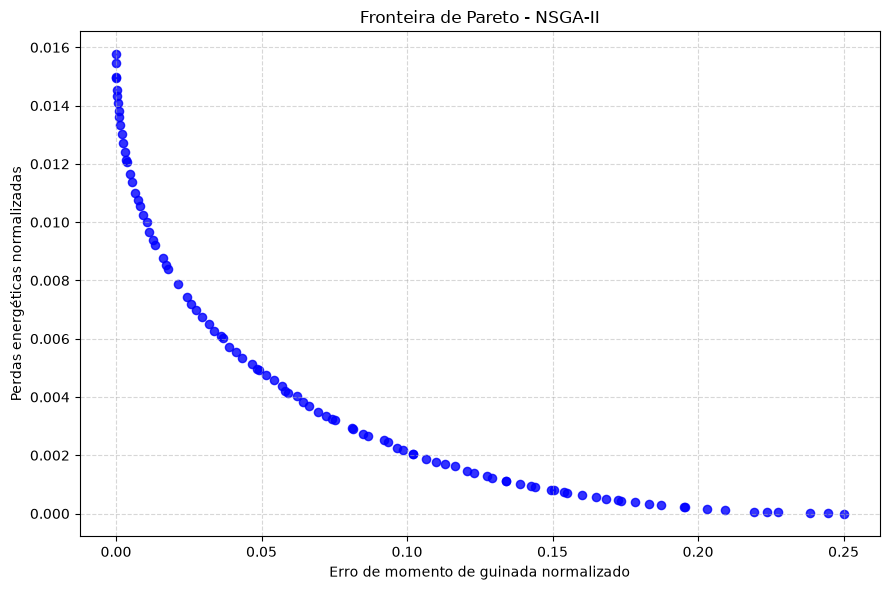

In [220]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    result.F[:, 0],
    result.F[:, 1],
    c='blue',
    s=35,
    alpha=0.8
)

plt.xlabel('Erro de momento de guinada normalizado')
plt.ylabel('Perdas energéticas normalizadas')

plt.title('Fronteira de Pareto - NSGA-II')

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()